In [1]:
import pandas as pd
import re
import matplotlib.pyplot as plt
import os
import numpy as np
import seaborn as sns

In [2]:
num_chiplets = 36
username = os.path.expanduser('~')
username

'/home/ehdgus7279'

In [3]:
# 소수점 아래 10자리까지 출력
pd.options.display.float_format = '{:.10f}'.format

In [4]:
benchmarks = [
    # Low-sharing Apps
    "fdtd2d", "jacobi1d", "fastwalshtransform", "relu", "fft", "fir", 
    "sssp", "convolution2d", "color", "bitonicsort", "pagerank", "simpleconvolution",

    # High-sharing Apps
    'gups',    
    'syr2k',
    'mm2', 
    'mm3', 
    'gemm',
    'gaussian',
    'gramschmidt',
    'vgg16',
    'spmv',
    'mis',
    'stencil2d',
    'lu',
    'matrixmultiplication',
    'matrixtranspose',
    'im2col',
    'nbody',
    'bfs',
]

In [5]:
clusters_3x3 = {
    'cluster_0_3x3': [0, 1, 2, 6, 7, 8, 12, 13, 14],
    'cluster_1_3x3': [3, 4, 5, 9, 10, 11, 15, 16, 17],
    'cluster_2_3x3': [18, 19, 20, 24, 25, 26, 30, 31, 32],
    'cluster_3_3x3': [21, 22, 23, 27, 28, 29, 33, 34, 35],
}

clusters_2x2 = {
    'cluster_0_2x2': [0, 1, 6, 7],       # 좌측 상단
    'cluster_1_2x2': [2, 3, 8, 9],       # 상단 중앙
    'cluster_2_2x2': [4, 5, 10, 11],     # 우측 상단
    'cluster_3_2x2': [12, 13, 18, 19],   # 좌측 중앙
    'cluster_4_2x2': [14, 15, 20, 21],   # 정중앙
    'cluster_5_2x2': [16, 17, 22, 23],   # 우측 중앙
    'cluster_6_2x2': [24, 25, 30, 31],   # 좌측 하단
    'cluster_7_2x2': [26, 27, 32, 33],   # 하단 중앙
    'cluster_8_2x2': [28, 29, 34, 35]    # 우측 하단
}

clusters_3x3_cols = [k for k in clusters_3x3.keys()]
clusters_2x2_cols = [k for k in clusters_2x2.keys()]

chiplet_to_cluster_2x2 = {}
for cluster_name, chiplet_ids in clusters_2x2.items():
    for chip_id in chiplet_ids:
        chiplet_to_cluster_2x2[chip_id] = cluster_name

chiplet_to_cluster_3x3 = {}
for cluster_name, chiplet_ids in clusters_3x3.items():
    for chip_id in chiplet_ids:
        chiplet_to_cluster_3x3[chip_id] = cluster_name

In [6]:
base_dir=f'{username}/mgvm/results/memory-traces'
date = "20260221-223953"
expanded_dir = f"{base_dir}/{date}/expanded"
trace_dir = f"{base_dir}/{date}"
print(f"{base_dir}/{date}")

/home/ehdgus7279/mgvm/results/memory-traces/20260221-223953


In [7]:
benchmark = 'spmv'
trace_file = f"{expanded_dir}/{benchmark}_mesh_6x6_memory_trace.csv"

df = pd.read_csv(trace_file, skipinitialspace=True)
df

,time,pc,addr,owner,rw,0,1,2,3,4,...,28,29,30,31,32,33,34,35,access_count,shared_chiplets
0,0.0153177130,377016576,2525024256,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,2,1
1,0.0153177150,377016576,2525024256,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,2,1
2,0.0153177170,377016576,2525024256,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,2,1
3,0.0153177190,377016576,2525024256,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,2,1
4,0.0153177260,377016576,2525024256,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,2,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127573790,0.0469619800,377016916,2331371904,33,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1
127573791,0.0469626920,377016968,2525312768,5,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1
127573792,0.0469626940,377016968,2525312832,5,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1
127573793,0.0469626940,377016968,2525312896,5,1,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1


In [8]:
top_pc_df = df[df['pc']==377016916]
top_pc_df

,time,pc,addr,owner,rw,0,1,2,3,4,...,28,29,30,31,32,33,34,35,access_count,shared_chiplets
984409,0.0153358870,377016916,2324807872,5,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1
986793,0.0153359240,377016916,2329271488,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1
987397,0.0153359340,377016916,2331593344,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1
987561,0.0153359360,377016916,2329257024,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1
990190,0.0153359820,377016916,2329226048,1,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
127573782,0.0469600990,377016916,2326727872,34,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1
127573783,0.0469605890,377016916,2319700096,35,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1
127573784,0.0469607950,377016916,2324379904,35,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1
127573785,0.0469612070,377016916,2328974784,33,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,1


In [9]:
def get_top_pc_df(df):
    curr_chip_cols = [str(i) for i in range(36)]

    # 1. 클러스터별 access 계산 (원본 로직 유지)
    for cluster_name, chiplet_ids in clusters_2x2.items():
        str_cols = [str(x) for x in chiplet_ids]
        df[cluster_name] = df[str_cols].sum(axis=1)

    for cluster_name, chiplet_ids in clusters_3x3.items():
        str_cols = [str(x) for x in chiplet_ids]
        df[cluster_name] = df[str_cols].sum(axis=1)

    # 3. addr 단위로 묶어서 Sharing 판별 (interval 제거)
    agg_dict = {col: 'sum' for col in curr_chip_cols}
    agg_dict.update({col: 'sum' for col in clusters_2x2})
    agg_dict.update({col: 'sum' for col in clusters_3x3})
    agg_dict['rw'] = 'max'
    agg_dict['owner'] = 'first'
    
    # 핵심: interval 없이 addr로만 그룹화
    addr_df = df.groupby('addr', as_index=False).agg(agg_dict)

    # 2x2, 3x3 클러스터 별 owner 설정
    addr_df['owner_cluster_2x2'] = addr_df['owner'].map(chiplet_to_cluster_2x2)
    addr_df['owner_cluster_3x3'] = addr_df['owner'].map(chiplet_to_cluster_3x3)

    # Owner 접근 마스킹 (기존 NumPy 로직 유지)
    def apply_mask(target_df, target_cols, owner_col):
        owner_vals = np.array(target_df[owner_col], dtype=str)[:, None]
        col_vals = np.array(target_cols, dtype=str)
        mask = (owner_vals == col_vals)
        target_df[target_cols] = target_df[target_cols].mask(mask, 0)
    
    apply_mask(addr_df, curr_chip_cols, 'owner')
    apply_mask(addr_df, list(clusters_2x2.keys()), 'owner_cluster_2x2')
    apply_mask(addr_df, list(clusters_3x3.keys()), 'owner_cluster_3x3')

    # Sharing 여부 및 Degree 계산
    addr_df['is_shared'] = (addr_df[curr_chip_cols] != 0).any(axis=1)
    addr_df['shared_degree'] = (addr_df[curr_chip_cols] != 0).sum(axis=1)
    addr_df['shared_degree_2x2'] = (addr_df[list(clusters_2x2.keys())] != 0).sum(axis=1)
    addr_df['shared_degree_3x3'] = (addr_df[list(clusters_3x3.keys())] != 0).sum(axis=1)

    addr_df['is_rw'] = addr_df['rw'] == 1
    addr_df['is_ro'] = addr_df['rw'] == 0

    # 4. 판별된 상태를 원본 데이터에 맵핑
    flags = addr_df[['addr', 'is_shared', 'is_rw', 'is_ro', 
                     'shared_degree', 'shared_degree_2x2', 'shared_degree_3x3']]
    
    # [수정] 만약 df에 이미 같은 이름의 컬럼이 있다면 삭제 후 병합 (중복 방지)
    cols_to_drop = [c for c in flags.columns if c in df.columns and c != 'addr']
    if cols_to_drop:
        df = df.drop(columns=cols_to_drop)
        
    df = df.merge(flags, on='addr', how='left')

    return df

In [10]:
def get_pc_metrics_per_time(df, time_interval=10000, ns=1e-9):
    curr_chip_cols = [str(i) for i in range(36)]

    # 1. 시간 정규화
    t_min = df['time'].min()
    df['norm_time'] = (df['time'] - t_min) / ns
    df['interval'] = (df['norm_time'] // time_interval) * time_interval

    # 2. interval별 전체 기준값들 (분모용)
    interval_total_cachelines_df = df.groupby('interval', as_index=False).agg(
        interval_total_cachelines=('addr', 'nunique')
    )
    interval_total_df = df.groupby('interval', as_index=False).agg(
        interval_total_access=('access_count', 'sum')
    )
    pc_interval_total_df = df.groupby(['interval', 'pc'], as_index=False).agg(
        pc_total_cachelines=('addr', 'nunique'),
        pc_total_access=('access_count', 'sum')
    )

    # 2x2, 3x3 클러스터 별 metric 추가
    for cluster_name, chiplet_ids in clusters_2x2.items():
        str_cols = [str(x) for x in chiplet_ids]
        df[cluster_name] = df[str_cols].sum(axis=1)

    for cluster_name, chiplet_ids in clusters_3x3.items():
        str_cols = [str(x) for x in chiplet_ids]
        df[cluster_name] = df[str_cols].sum(axis=1)

    # ---------------------------------------------------------
    # 3. 👇 핵심 수정 로직: interval × addr 단위로 묶어서 Sharing 판별
    # ---------------------------------------------------------
    agg_dict = {col: 'sum' for col in curr_chip_cols}
    agg_dict.update({col: 'sum' for col in clusters_2x2})
    agg_dict.update({col: 'sum' for col in clusters_3x3})
    agg_dict['rw'] = 'max'     # 1이 하나라도 있으면 RW 캐시라인
    agg_dict['owner'] = 'first' # owner는 동일하므로 하나만 취함
    
    interval_addr_df = df.groupby(['interval', 'addr'], as_index=False).agg(agg_dict)

    # 2x2, 3x3 클러스터 별 owner 설정
    interval_addr_df['owner_cluster_2x2'] = interval_addr_df['owner'].map(chiplet_to_cluster_2x2)
    interval_addr_df['owner_cluster_3x3'] = interval_addr_df['owner'].map(chiplet_to_cluster_3x3)

    # NumPy 기반 벡터화 마스킹 (owner 접근 0으로 치환)
    owner_vals = np.array(interval_addr_df['owner'], dtype=str)[:, None]
    col_vals = np.array(curr_chip_cols, dtype=str)
    is_owner = owner_vals == col_vals
    interval_addr_df[curr_chip_cols] = interval_addr_df[curr_chip_cols].mask(is_owner, 0)

    # 2x2, 3x3 클러스터 별 NumPy 기반 벡터화 마스킹 (owner 접근 0으로 치환)
    owner_vals_2x2 = np.array(interval_addr_df['owner_cluster_2x2'], dtype=str)[:, None]
    col_vals_2x2 = np.array(clusters_2x2_cols, dtype=str)
    is_owner_2x2 = owner_vals_2x2 == col_vals_2x2
    interval_addr_df[clusters_2x2_cols] = interval_addr_df[clusters_2x2_cols].mask(is_owner_2x2, 0)

    owner_vals_3x3 = np.array(interval_addr_df['owner_cluster_3x3'], dtype=str)[:, None]
    col_vals_3x3 = np.array(clusters_3x3_cols, dtype=str)
    is_owner_3x3 = owner_vals_3x3 == col_vals_3x3
    interval_addr_df[clusters_3x3_cols] = interval_addr_df[clusters_3x3_cols].mask(is_owner_3x3, 0)

    # Sharing 여부 및 Sharing Degree(공유된 칩렛 개수) 계산
    interval_addr_df['is_shared'] = (interval_addr_df[curr_chip_cols] != 0).any(axis=1)
    interval_addr_df['shared_degree'] = (interval_addr_df[curr_chip_cols] != 0).sum(axis=1)
    interval_addr_df['shared_degree_2x2'] = (interval_addr_df[clusters_2x2_cols] != 0).sum(axis=1)
    interval_addr_df['shared_degree_3x3'] = (interval_addr_df[clusters_3x3_cols] != 0).sum(axis=1)
    
    # interval 기준 RO/RW 판별
    interval_addr_df['is_rw_interval'] = interval_addr_df['rw'] == 1
    interval_addr_df['is_ro_interval'] = interval_addr_df['rw'] == 0

    # ---------------------------------------------------------
    # 4. 판별된 상태(Flag)를 원본 데이터에 맵핑
    # ---------------------------------------------------------
    flags = interval_addr_df[['interval', 'addr', 
                              'is_shared', 'is_rw_interval', 'is_ro_interval', 
                              'shared_degree', 'shared_degree_2x2', 'shared_degree_3x3']]
    df = df.merge(flags, on=['interval', 'addr'], how='left')

    return df

In [11]:
top_pc_detailed_df = get_top_pc_df(top_pc_df)

In [12]:
top_pc_per_time_df = get_pc_metrics_per_time(top_pc_df)

In [14]:
top_pc_per_time_df

,time,pc,addr,owner,rw,0,1,2,3,4,...,cluster_2_3x3,cluster_3_3x3,norm_time,interval,is_shared,is_rw_interval,is_ro_interval,shared_degree,shared_degree_2x2,shared_degree_3x3
0,0.0153358870,377016916,2324807872,5,0,0,0,0,0,0,...,1,0,0.0000000000,0.0000000000,True,False,True,1,1,1
1,0.0153359240,377016916,2329271488,1,0,0,0,0,0,0,...,1,0,37.0000000013,0.0000000000,True,False,True,2,1,2
2,0.0153359340,377016916,2331593344,1,0,0,0,0,0,0,...,1,0,47.0000000013,0.0000000000,True,False,True,1,1,1
3,0.0153359360,377016916,2329257024,1,0,0,0,0,0,0,...,1,0,49.0000000002,0.0000000000,True,False,True,2,2,1
4,0.0153359820,377016916,2329226048,1,0,0,0,0,0,0,...,1,0,95.0000000003,0.0000000000,True,False,True,1,1,1
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
43688059,0.0469600990,377016916,2326727872,34,0,0,0,0,0,0,...,0,0,31624211.9999999963,31620000.0000000000,True,False,True,1,1,1
43688060,0.0469605890,377016916,2319700096,35,0,0,0,0,0,0,...,0,0,31624701.9999999963,31620000.0000000000,True,False,True,1,1,1
43688061,0.0469607950,377016916,2324379904,35,0,0,0,0,0,0,...,0,0,31624908.0000000000,31620000.0000000000,True,False,True,1,1,1
43688062,0.0469612070,377016916,2328974784,33,0,0,0,0,0,0,...,0,0,31625319.9999999963,31620000.0000000000,True,False,True,1,1,1


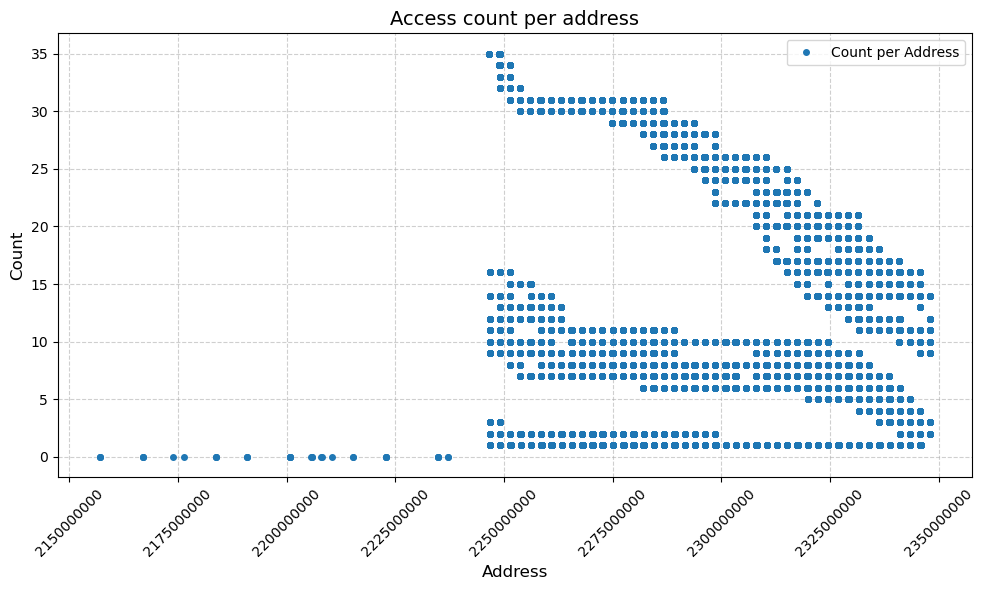

In [17]:
plt.figure(figsize=(10, 6)) 
plt.plot(top_pc_detailed_df['addr'], top_pc_detailed_df['shared_degree'], 'o', label='Count per Address', markersize=4)

plt.title('Access count per address', fontsize=14)
plt.xlabel('Address', fontsize=12)
plt.ylabel('Shared Degree', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

plt.ticklabel_format(style='plain', axis='x')
plt.xticks(rotation=45)

plt.legend()
plt.tight_layout()

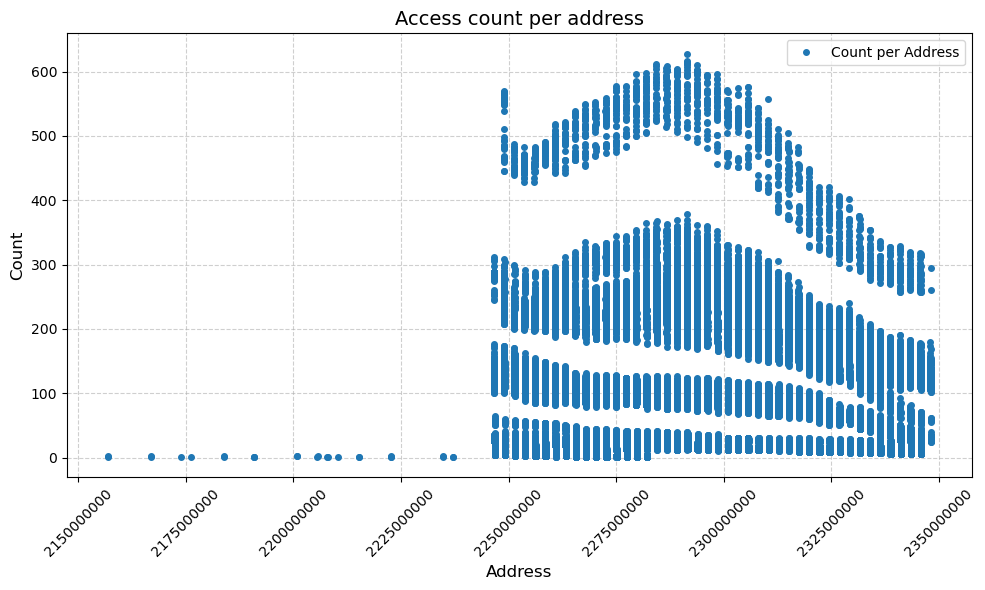

In [11]:
plt.figure(figsize=(10, 6)) 
plt.plot(top_pc_df['addr'], top_pc_df['access_count'], 'o', label='Count per Address', markersize=4)

plt.title('Access count per address', fontsize=14)
plt.xlabel('Address', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.grid(True, linestyle='--', alpha=0.6)

plt.ticklabel_format(style='plain', axis='x')
plt.xticks(rotation=45)

plt.legend()
plt.tight_layout()